# Segment and Error Analysis

> Who does the recommender work for, where do its hits come from, and what happens at the cold edges?

The ablation (`reports/phase4_ablation.md`) gives one number per model averaged over the 1,000-user
reporting cohort. This notebook breaks those averages apart on the same cohort, same holdout and same
train-split models, so every number here reconciles with the published table:

1. **User activity**: NDCG@10 and hit rate by quartile of training-set rating count
2. **Item popularity**: which popularity decile the hits land in, for popularity, MF and the hybrid
3. **Cold start**: users with fewer than 5 training ratings against everyone else
4. **Misses**: five sampled users where the hybrid missed, with the held-out title and what it recommended instead

**Protocol.** One random interaction per user is held out (`src/eval/splits.py::build_validation`);
every model ranks the full catalog minus the user's training history. The *hybrid* is the served blend
(`DEFAULT_HYBRID_WEIGHTS`, the Task 0.6 re-tune: kNN 0.952, MF 0.048, popularity 0.0003). Implicit ALS
(`reports/mf_diagnostic.md`) is not served; it is included as the reference first-stage model.
Intervals are 95% percentile bootstrap over users (`src/eval/bootstrap.py`).

Figures are written to `reports/figures/segments/`. Building the cohort's lists takes about 10 minutes
(item-kNN scores the full catalog for each user); the train-split models are cached under
`experiments/artifacts/` after their first fit.

In [1]:
from __future__ import annotations

import os
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use('seaborn-v0_8')
pd.set_option('display.max_colwidth', 120)


def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'src').exists() and (p / 'data').exists() and ((p / 'requirements.txt').exists() or (p / '.git').exists()):
            return p
    return start


ROOT = find_project_root(Path.cwd())
print(f'Project root: {ROOT}')

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# src.models.constants resolves data/ and experiments/ relative to the repo root.
os.chdir(ROOT)

FIG_DIR = ROOT / 'reports' / 'figures' / 'segments'
FIG_DIR.mkdir(parents=True, exist_ok=True)

K = 10
# Lists are ranked deeper than K so the misses table can say how far down the held-out title sat.
K_MAX = 200

Project root: C:\Users\dedwa\OneDrive\Desktop\Dromund_Kass\MARS\MyAnimeRecommendationSystem


## 1) Per-user recommendation lists

`scripts/evaluate_hybrid.py::cohort_recommendations` is the function the ablation's CF rows come from;
it returns each user's ranked list instead of only the aggregates. Passing the served weights as the
primary blend makes `hybrid_weighted` the served hybrid.

In [2]:
from scripts.evaluate_hybrid import cohort_recommendations
from src.models.constants import DEFAULT_HYBRID_WEIGHTS, REPORTING_COHORT_USERS

t0 = time.perf_counter()
cohort = cohort_recommendations(
    REPORTING_COHORT_USERS,
    K_MAX,
    w_mf=DEFAULT_HYBRID_WEIGHTS['mf'],
    w_knn=DEFAULT_HYBRID_WEIGHTS['knn'],
    w_pop=DEFAULT_HYBRID_WEIGHTS['pop'],
)
print(f'Built {len(cohort["users"]):,} users x {len(cohort["recs"])} models in {time.perf_counter() - t0:.0f}s')

users = cohort['users']
train_hist = cohort['train_hist']
heldout = cohort['val_df'].set_index('user_id').loc[users]

Built 1,000 users x 7 models in 560s


In [3]:
from src.eval.metrics import ndcg_at_k

MODELS = {
    'popularity': 'Popularity',
    'mf_sgd': 'MF (FunkSVD)',
    'item_knn_sklearn': 'Item-kNN',
    'hybrid_weighted': 'Hybrid (served)',
    'implicit_als': 'Implicit ALS (not served)',
}
PALETTE = dict(zip(MODELS.values(), sns.color_palette('colorblind', len(MODELS))))

rows = []
for u in users:
    item = int(heldout.at[u, 'anime_id'])
    for m, label in MODELS.items():
        recs = cohort['recs'][m][u]
        rows.append(
            {
                'user_id': u,
                'model': label,
                'n_train': len(train_hist.get(u, ())),
                'heldout_id': item,
                'heldout_rating': int(heldout.at[u, 'rating']),
                'ndcg': ndcg_at_k(recs, {item}, K),
                'hit': float(item in recs[:K]),
                'rank': recs.index(item) + 1 if item in recs else np.nan,
            }
        )
per_user = pd.DataFrame(rows)
per_user['model'] = pd.Categorical(per_user['model'], list(MODELS.values()))

overall = per_user.groupby('model', observed=True)[['ndcg', 'hit']].mean()
overall.columns = [f'NDCG@{K}', f'hit rate@{K}']
display(overall.round(4))

,NDCG@10,hit rate@10
model,,
Popularity,0.0347,0.065
MF (FunkSVD),0.0282,0.048
Item-kNN,0.0632,0.101
Hybrid (served),0.0658,0.111
Implicit ALS (not served),0.1890,0.311


These are the ablation's NDCG@10 rows (popularity 0.0347, MF 0.0282, item-kNN 0.0632, hybrid 0.0658,
ALS 0.1890), so the segments below split the published numbers rather than a new run. With one held-out
item per user, hit rate@10 is the share of users whose held-out title made the top 10.

In [4]:
expected = {'Popularity': 0.0347, 'MF (FunkSVD)': 0.0282, 'Item-kNN': 0.0632, 'Hybrid (served)': 0.0658, 'Implicit ALS (not served)': 0.1890}
for label, value in expected.items():
    assert abs(overall.loc[label, f'NDCG@{K}'] - value) < 5e-4, (label, overall.loc[label, f'NDCG@{K}'], value)
print('Matches reports/phase4_ablation.md')

Matches reports/phase4_ablation.md


In [5]:
from src.eval.bootstrap import bootstrap_mean_ci


def segment_table(df: pd.DataFrame, segment: str) -> pd.DataFrame:
    out = []
    for (seg, model), g in df.groupby([segment, 'model'], observed=True):
        n_mean, n_lo, n_hi = bootstrap_mean_ci(g['ndcg'])
        h_mean, h_lo, h_hi = bootstrap_mean_ci(g['hit'])
        out.append(
            {
                segment: seg,
                'model': model,
                'users': len(g),
                'ndcg': n_mean,
                'ndcg_lo': n_lo,
                'ndcg_hi': n_hi,
                'hit': h_mean,
                'hit_lo': h_lo,
                'hit_hi': h_hi,
            }
        )
    return pd.DataFrame(out)


def show_table(t: pd.DataFrame, segment: str) -> None:
    view = pd.DataFrame(
        {
            segment: t[segment],
            'model': t['model'],
            'users': t['users'],
            f'NDCG@{K} [95% CI]': [f'{m:.4f} [{lo:.4f}, {hi:.4f}]' for m, lo, hi in zip(t['ndcg'], t['ndcg_lo'], t['ndcg_hi'])],
            f'hit rate@{K} [95% CI]': [f'{m:.3f} [{lo:.3f}, {hi:.3f}]' for m, lo, hi in zip(t['hit'], t['hit_lo'], t['hit_hi'])],
        }
    )
    display(view.set_index([segment, 'model']))


def bar_with_ci(t: pd.DataFrame, segment: str, metric: str, ax, title: str) -> None:
    segs = list(dict.fromkeys(t[segment]))
    models = list(dict.fromkeys(t['model']))
    width = 0.8 / len(models)
    x = np.arange(len(segs))
    for i, model in enumerate(models):
        g = t[t['model'] == model].set_index(segment).loc[segs]
        err = np.vstack([g[metric] - g[f'{metric}_lo'], g[f'{metric}_hi'] - g[metric]])
        ax.bar(x + (i - (len(models) - 1) / 2) * width, g[metric], width, yerr=err, capsize=2, label=model, color=PALETTE[model])
    ax.set_xticks(x)
    ax.set_xticklabels(segs)
    ax.set_title(title)

## 2) By user activity

Users are split into quartiles of their training-set interaction count (the rating history the models
see). The cohort is a uniform sample of validation users, so each quartile holds about 250 users.

In [6]:
users_df = per_user.drop_duplicates('user_id')[['user_id', 'n_train']].copy()
users_df['activity'], edges = pd.qcut(users_df['n_train'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)
per_user = per_user.merge(users_df[['user_id', 'activity']], on='user_id')

bounds = users_df.groupby('activity', observed=True)['n_train'].agg(['min', 'median', 'max', 'size'])
bounds.columns = ['min train ratings', 'median', 'max', 'users']
display(bounds)

by_activity = segment_table(per_user, 'activity')
show_table(by_activity, 'activity')

,min train ratings,median,max,users
activity,,,,
Q1,0,7.0,20,251
Q2,21,39.0,62,249
Q3,63,95.0,135,252
Q4,136,222.5,1172,248


users         NDCG@10 [95% CI]  \
activity model                                                       
Q1       Popularity                   251  0.0367 [0.0217, 0.0524]   
         MF (FunkSVD)                 251  0.0621 [0.0371, 0.0901]   
         Item-kNN                     251  0.0861 [0.0551, 0.1174]   
         Hybrid (served)              251  0.1031 [0.0742, 0.1365]   
         Implicit ALS (not served)    251  0.2016 [0.1646, 0.2434]   
Q2       Popularity                   249  0.0412 [0.0228, 0.0629]   
         MF (FunkSVD)                 249  0.0151 [0.0048, 0.0284]   
         Item-kNN                     249  0.0638 [0.0387, 0.0891]   
         Hybrid (served)              249  0.0559 [0.0334, 0.0796]   
         Implicit ALS (not served)    249  0.2587 [0.2129, 0.3044]   
Q3       Popularity                   252  0.0296 [0.0148, 0.0481]   
         MF (FunkSVD)                 252  0.0157 [0.0037, 0.0313]   
         Item-kNN                     252  0.0464 [0.0258, 0.0689]   
         Hybrid (served)              252  0.0496 [0.0278, 0.0746]   
         Implicit ALS (not served)    252  0.1408 [0.1079, 0.1774]   
Q4       Popularity                   248  0.0311 [0.0137, 0.0510]   
         MF (FunkSVD)                 248  0.0196 [0.0073, 0.0340]   
         Item-kNN                     248  0.0565 [0.0344, 0.0803]   
         Hybrid (served)              248  0.0547 [0.0312, 0.0788]   
         Implicit ALS (not served)    248  0.1553 [0.1201, 0.1925]   

                                    hit rate@10 [95% CI]  
activity model                                            
Q1       Popularity                 0.088 [0.052, 0.124]  
         MF (FunkSVD)               0.100 [0.064, 0.139]  
         Item-kNN                   0.116 [0.076, 0.151]  
         Hybrid (served)            0.163 [0.120, 0.207]  
         Implicit ALS (not served)  0.315 [0.259, 0.375]  
Q2       Popularity                 0.068 [0.040, 0.100]  
         MF (FunkSVD)               0.032 [0.012, 0.056]  
         Item-kNN                   0.108 [0.068, 0.145]  
         Hybrid (served)            0.100 [0.064, 0.141]  
         Implicit ALS (not served)  0.410 [0.349, 0.470]  
Q3       Popularity                 0.056 [0.032, 0.083]  
         MF (FunkSVD)               0.024 [0.008, 0.044]  
         Item-kNN                   0.079 [0.048, 0.111]  
         Hybrid (served)            0.091 [0.056, 0.131]  
         Implicit ALS (not served)  0.262 [0.206, 0.321]  
Q4       Popularity                 0.048 [0.024, 0.077]  
         MF (FunkSVD)               0.036 [0.016, 0.060]  
         Item-kNN                   0.101 [0.065, 0.137]  
         Hybrid (served)            0.089 [0.056, 0.125]  
         Implicit ALS (not served)  0.258 [0.206, 0.315]

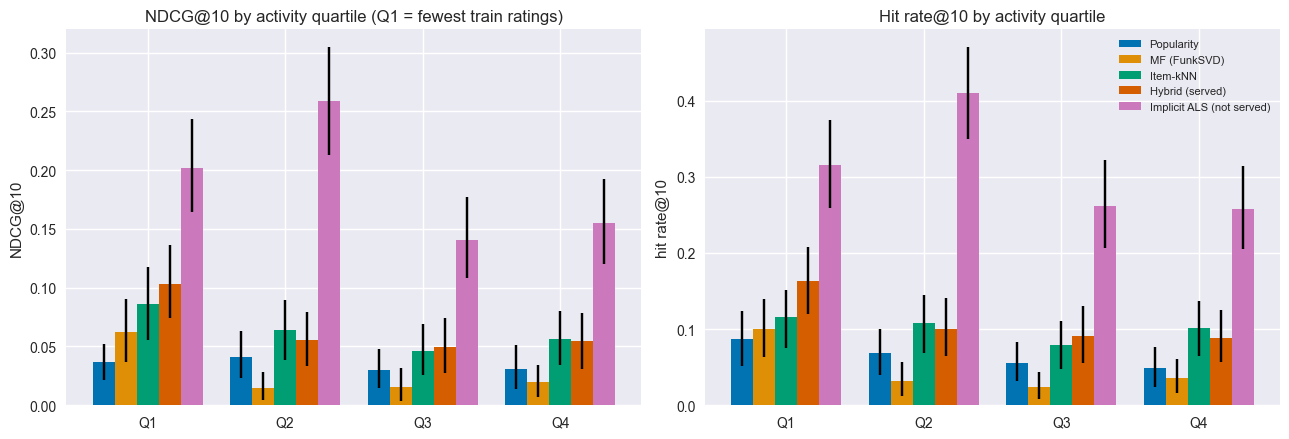

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_with_ci(by_activity, 'activity', 'ndcg', axes[0], f'NDCG@{K} by activity quartile (Q1 = fewest train ratings)')
bar_with_ci(by_activity, 'activity', 'hit', axes[1], f'Hit rate@{K} by activity quartile')
axes[0].set_ylabel(f'NDCG@{K}')
axes[1].set_ylabel(f'hit rate@{K}')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / 'ndcg_hit_by_activity_quartile.png', dpi=150)
plt.show()

In [8]:
from src.eval.bootstrap import paired_bootstrap_diff_ci

wide = per_user.pivot_table(index=['user_id', 'activity'], columns='model', values='ndcg', observed=True).reset_index()
diffs = []
for q, g in wide.groupby('activity', observed=True):
    for other in ['Popularity', 'Item-kNN']:
        d, lo, hi = paired_bootstrap_diff_ci(g['Hybrid (served)'], g[other])
        diffs.append({'activity': q, 'comparison': f'hybrid - {other}', f'NDCG@{K} diff [95% CI]': f'{d:+.4f} [{lo:+.4f}, {hi:+.4f}]'})
display(pd.DataFrame(diffs).set_index(['activity', 'comparison']))

NDCG@10 diff [95% CI]
activity comparison                                     
Q1       hybrid - Popularity  +0.0664 [+0.0378, +0.1005]
         hybrid - Item-kNN    +0.0170 [+0.0017, +0.0333]
Q2       hybrid - Popularity  +0.0146 [-0.0125, +0.0394]
         hybrid - Item-kNN    -0.0080 [-0.0188, +0.0028]
Q3       hybrid - Popularity  +0.0199 [-0.0042, +0.0424]
         hybrid - Item-kNN    +0.0032 [-0.0084, +0.0139]
Q4       hybrid - Popularity  +0.0236 [+0.0007, +0.0452]
         hybrid - Item-kNN    -0.0019 [-0.0102, +0.0075]

Why does the blend beat item-kNN only in Q1? Offline item-kNN (`ItemKNNRecommender.score_all`) returns
no list at all for some users: those with no training history, and those whose training ratings are all
equal, because centering turns a uniform profile into zeros. The blend sums raw source scores, so when
kNN is silent its MF and popularity terms rank alone. Splitting each quartile by whether kNN produced a list:

In [9]:
train_ratings = cohort['train_df'][cohort['train_df']['user_id'].isin(users)].groupby('user_id')['rating']
uniform_value = train_ratings.agg(lambda r: r.iloc[0] if r.nunique() == 1 else np.nan)


def knn_status(u: int) -> str:
    if cohort['recs']['item_knn_sklearn'][u]:
        return 'kNN list'
    if not train_hist.get(u):
        return 'no list: no train history'
    v = uniform_value.get(u, np.nan)
    if v == 0:
        return 'no list: every train rating 0 (watched, unrated)'
    if pd.notna(v):
        return 'no list: every train rating equal, non-zero'
    return 'no list: other'


users_df['knn_status'] = users_df['user_id'].map(knn_status)
display(pd.crosstab(users_df['knn_status'], users_df['activity'], margins=True))

wide = wide.merge(users_df[['user_id', 'knn_status']], on='user_id')
split = []
for q, g in wide.groupby('activity', observed=True):
    scored = g[g['knn_status'] == 'kNN list']
    d, lo, hi = paired_bootstrap_diff_ci(scored['Hybrid (served)'], scored['Item-kNN'])
    unscored = g[g['knn_status'] != 'kNN list']
    split.append(
        {
            'activity': q,
            'users kNN scores': len(scored),
            f'hybrid - kNN on them [95% CI]': f'{d:+.4f} [{lo:+.4f}, {hi:+.4f}]',
            'users kNN cannot score': len(unscored),
            f'hybrid NDCG@{K} on them': round(unscored['Hybrid (served)'].mean(), 4) if len(unscored) else np.nan,
        }
    )
display(pd.DataFrame(split).set_index('activity'))

activity,Q1,Q2,Q3,Q4,All
knn_status,,,,,
kNN list,177,234,241,235,887
"no list: every train rating 0 (watched, unrated)",12,14,11,12,49
"no list: every train rating equal, non-zero",29,1,0,1,31
no list: no train history,33,0,0,0,33
All,251,249,252,248,1000


,users kNN scores,hybrid - kNN on them [95% CI],users kNN cannot score,hybrid NDCG@10 on them
activity,,,,
Q1,177,"-0.0024 [-0.0147, +0.0107]",74,0.0633
Q2,234,"-0.0085 [-0.0207, +0.0031]",15,0.0000
Q3,241,"+0.0033 [-0.0086, +0.0145]",11,0.0000
Q4,235,"-0.0020 [-0.0119, +0.0072]",13,0.0000


**Takeaway.** Item-kNN, MF and the hybrid all score best on the least active quarter (at most 20 training ratings; hybrid 0.1031 against 0.0547 in the most active), and that is the only quartile where the hybrid beats item-kNN (+0.0170, paired CI above zero). The whole edge comes from the 74 Q1 users kNN cannot score: on the users it can score, the hybrid ties kNN in every quartile, and on the 37 Q2-Q4 users it cannot (all-0 raters) the hybrid also scores 0, so the served blend is item-kNN plus a fallback that only works for light users.

## 3) Where the hits come from: item popularity

Items are ranked by their training-set interaction count and cut into ten equal-sized deciles
(D10 = the most-watched tenth of the catalog). For each model, every hit (held-out title in the top 10)
is assigned the decile of the title it hit. The grey bars are where the held-out titles themselves
fall: what a model that hit every user would show.

In [10]:
item_counts = pd.Series(Counter(i for hist in train_hist.values() for i in hist))
deciles = pd.qcut(item_counts.rank(method='first'), 10, labels=[f'D{i}' for i in range(1, 11)])
decile_of = deciles.to_dict()
DECILES = [f'D{i}' for i in range(1, 11)]

decile_bounds = item_counts.groupby(deciles, observed=True).agg(['min', 'max', 'size'])
decile_bounds.columns = ['min train interactions', 'max', 'items']
decile_bounds['share of train interactions'] = (item_counts.groupby(deciles, observed=True).sum() / item_counts.sum()).round(4)
display(decile_bounds)

per_user['heldout_decile'] = per_user['heldout_id'].map(decile_of).fillna('unseen in train')
print('held-out titles with no train interactions:', int((per_user.drop_duplicates('user_id')['heldout_decile'] == 'unseen in train').sum()))

,min train interactions,max,items,share of train interactions
D1,1,1,1120,0.0001
D2,1,3,1120,0.0003
D3,3,9,1120,0.0008
D4,9,24,1120,0.0022
D5,24,51,1120,0.0053
D6,51,107,1120,0.0110
D7,108,242,1120,0.0234
D8,243,629,1120,0.0582
D9,629,1800,1120,0.1585
D10,1802,38208,1120,0.7402


held-out titles with no train interactions: 0


In [11]:
HIT_MODELS = ['Popularity', 'MF (FunkSVD)', 'Hybrid (served)', 'Implicit ALS (not served)']

heldout_share = per_user.drop_duplicates('user_id')['heldout_decile'].value_counts(normalize=True).reindex(DECILES, fill_value=0.0)
hit_share = {'held-out titles (all users)': heldout_share}
hit_counts = {'held-out titles (all users)': len(users)}
for model in HIT_MODELS:
    hits = per_user[(per_user['model'] == model) & (per_user['hit'] == 1.0)]
    hit_share[model] = hits['heldout_decile'].value_counts(normalize=True).reindex(DECILES, fill_value=0.0)
    hit_counts[model] = len(hits)

share_df = pd.DataFrame(hit_share)
share_df.loc['hits (n)'] = pd.Series(hit_counts)
display(share_df.round(3))

,held-out titles (all users),Popularity,MF (FunkSVD),Hybrid (served),Implicit ALS (not served)
heldout_decile,,,,,
D1,0.000,0.0,0.0,0.000,0.000
D2,0.000,0.0,0.0,0.000,0.000
D3,0.001,0.0,0.0,0.000,0.000
D4,0.000,0.0,0.0,0.000,0.000
D5,0.001,0.0,0.0,0.000,0.000
D6,0.004,0.0,0.0,0.000,0.000
D7,0.012,0.0,0.0,0.000,0.000
D8,0.028,0.0,0.0,0.009,0.000
D9,0.109,0.0,0.0,0.072,0.019


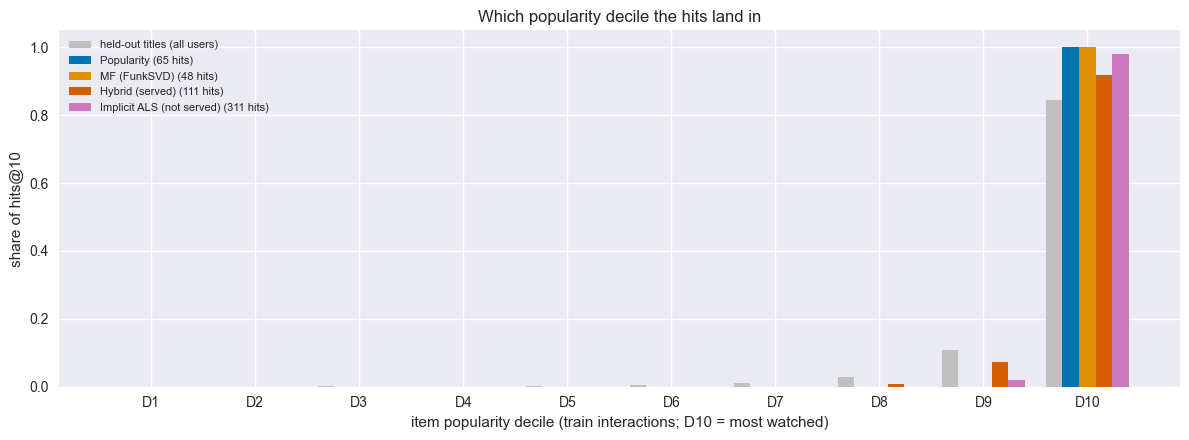

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(DECILES))
width = 0.8 / (len(HIT_MODELS) + 1)
ax.bar(x - 0.4 + width / 2, share_df.loc[DECILES, 'held-out titles (all users)'], width, color='0.75', label='held-out titles (all users)')
for i, model in enumerate(HIT_MODELS, start=1):
    ax.bar(x - 0.4 + width / 2 + i * width, share_df.loc[DECILES, model], width, color=PALETTE[model], label=f'{model} ({hit_counts[model]} hits)')
ax.set_xticks(x)
ax.set_xticklabels(DECILES)
ax.set_xlabel('item popularity decile (train interactions; D10 = most watched)')
ax.set_ylabel(f'share of hits@{K}')
ax.set_title('Which popularity decile the hits land in')
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / 'hit_share_by_popularity_decile.png', dpi=150)
plt.show()

In [13]:
rec_decile = {}
for model in HIT_MODELS:
    key = next(k for k, v in MODELS.items() if v == model)
    slots = [decile_of.get(i, 'unseen in train') for u in users for i in cohort['recs'][key][u][:K]]
    rec_decile[model] = pd.Series(slots).value_counts(normalize=True).reindex(DECILES, fill_value=0.0)
rec_decile_df = pd.DataFrame(rec_decile)
print(f'Share of all top-{K} slots by decile (what each model recommends, hit or not):')
display(rec_decile_df.loc[['D7', 'D8', 'D9', 'D10']].round(3))

Share of all top-10 slots by decile (what each model recommends, hit or not):


,Popularity,MF (FunkSVD),Hybrid (served),Implicit ALS (not served)
D7,0.0,0.019,0.005,0.000
D8,0.0,0.025,0.010,0.001
D9,0.0,0.132,0.045,0.019
D10,1.0,0.688,0.864,0.980


**Takeaway.** Held-out titles already sit in the head (84.5% in D10, the tenth of the catalog that holds 74% of training interactions), and the models concentrate further: every popularity and MF hit is a D10 title, as are 98.1% of implicit ALS's. The hybrid is the only model with a real share of hits outside D10 (8.1%, nearly all D9), but below D9, where 4.6% of held-out titles sit, it makes one hit in 1,000 users, so its higher catalog coverage has not yet turned into accuracy in the tail.

## 4) Cold start: fewer than 5 training ratings

A *cold* user has fewer than 5 interactions in the training split. Users whose only interaction was
the held-out one have no history at all, and every CF model returns nothing for them
(`reports/mf_diagnostic.md`, section 5); popularity still ranks for them.

In [14]:
COLD_MAX = 5
users_df['segment'] = pd.Categorical(
    np.where(users_df['n_train'] < COLD_MAX, f'cold (< {COLD_MAX} train ratings)', 'warm'),
    ['warm', f'cold (< {COLD_MAX} train ratings)'],
)
per_user = per_user.merge(users_df[['user_id', 'segment']], on='user_id')

cold_users = users_df[users_df['n_train'] < COLD_MAX]
print(f'cold users: {len(cold_users)} of {len(users_df)}; of those, {int((cold_users["n_train"] == 0).sum())} have no training history')
print('train-rating counts among cold users:', cold_users['n_train'].value_counts().sort_index().to_dict())

by_segment = segment_table(per_user, 'segment')
show_table(by_segment, 'segment')

empty = per_user[per_user['segment'] != 'warm'].assign(empty=lambda d: [len(cohort['recs'][next(k for k, v in MODELS.items() if v == m)][u]) == 0 for u, m in zip(d['user_id'], d['model'])])
print('cold users with an empty list, by model:', empty.groupby('model', observed=True)['empty'].sum().astype(int).to_dict())

cold users: 95 of 1000; of those, 33 have no training history
train-rating counts among cold users: {0: 33, 1: 20, 2: 10, 3: 13, 4: 19}


users  \
segment                  model                              
warm                     Popularity                   905   
                         MF (FunkSVD)                 905   
                         Item-kNN                     905   
                         Hybrid (served)              905   
                         Implicit ALS (not served)    905   
cold (< 5 train ratings) Popularity                    95   
                         MF (FunkSVD)                  95   
                         Item-kNN                      95   
                         Hybrid (served)               95   
                         Implicit ALS (not served)     95   

                                                           NDCG@10 [95% CI]  \
segment                  model                                                
warm                     Popularity                 0.0348 [0.0246, 0.0447]   
                         MF (FunkSVD)               0.0274 [0.0185, 0.0370]   
                         Item-kNN                   0.0676 [0.0547, 0.0829]   
                         Hybrid (served)            0.0671 [0.0546, 0.0818]   
                         Implicit ALS (not served)  0.2010 [0.1794, 0.2206]   
cold (< 5 train ratings) Popularity                 0.0337 [0.0131, 0.0570]   
                         MF (FunkSVD)               0.0354 [0.0096, 0.0704]   
                         Item-kNN                   0.0211 [0.0000, 0.0526]   
                         Hybrid (served)            0.0532 [0.0201, 0.0891]   
                         Implicit ALS (not served)  0.0748 [0.0344, 0.1230]   

                                                    hit rate@10 [95% CI]  
segment                  model                                            
warm                     Popularity                 0.063 [0.046, 0.078]  
                         MF (FunkSVD)               0.046 [0.033, 0.060]  
                         Item-kNN                   0.109 [0.091, 0.131]  
                         Hybrid (served)            0.113 [0.094, 0.134]  
                         Implicit ALS (not served)  0.331 [0.299, 0.360]  
cold (< 5 train ratings) Popularity                 0.084 [0.032, 0.137]  
                         MF (FunkSVD)               0.063 [0.021, 0.116]  
                         Item-kNN                   0.021 [0.000, 0.053]  
                         Hybrid (served)            0.095 [0.042, 0.147]  
                         Implicit ALS (not served)  0.116 [0.053, 0.179]

cold users with an empty list, by model: {'Popularity': 0, 'MF (FunkSVD)': 33, 'Item-kNN': 62, 'Hybrid (served)': 0, 'Implicit ALS (not served)': 33}


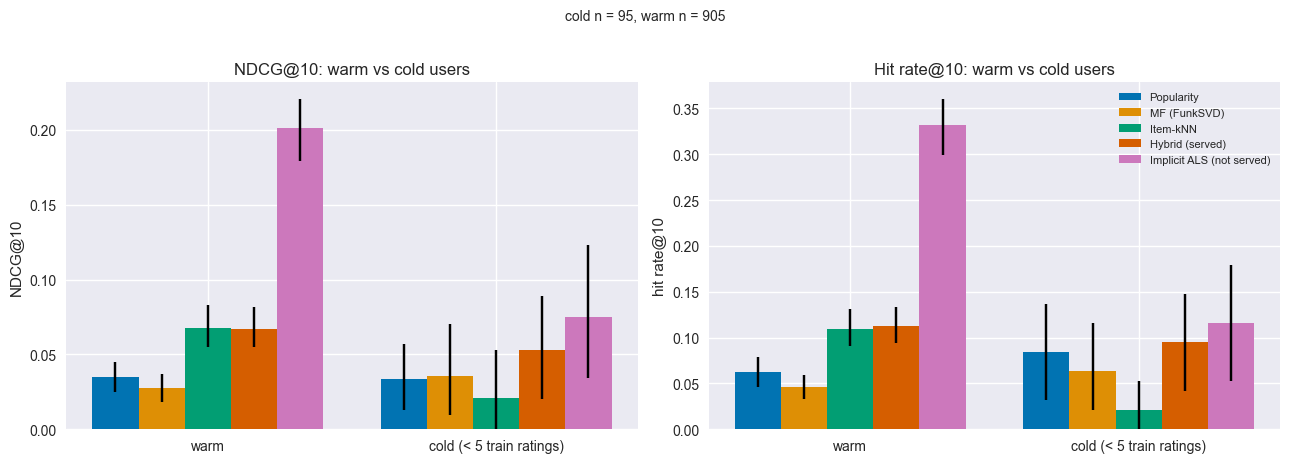

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_with_ci(by_segment, 'segment', 'ndcg', axes[0], f'NDCG@{K}: warm vs cold users')
bar_with_ci(by_segment, 'segment', 'hit', axes[1], f'Hit rate@{K}: warm vs cold users')
axes[0].set_ylabel(f'NDCG@{K}')
axes[1].set_ylabel(f'hit rate@{K}')
axes[1].legend(loc='upper right', fontsize=8)
fig.suptitle(f"cold n = {len(cold_users)}, warm n = {len(users_df) - len(cold_users)}", y=1.02, fontsize=10)
plt.tight_layout()
fig.savefig(FIG_DIR / 'cold_vs_warm.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway.** 9.5% of the cohort is cold (95 users, 33 with no history at all), and item-kNN collapses there (0.0211 NDCG@10, no list for 62 of the 95) while the hybrid keeps 0.0532 against 0.0671 for warm users, because the blend's MF and popularity terms rank alone when kNN is silent. That fallback was never designed: it falls out of summing raw scores, nothing in the code declares it, and at n = 95 its interval cannot separate it from popularity alone (0.0337) or from implicit ALS (0.0748).

## 5) Misses: what the hybrid recommended instead

Five users sampled (seed 42) from those whose held-out title is not in the hybrid's top 10. For each:
the titles they rated highest in training, the held-out title and its rating, how far down the
hybrid's list it sat (out of the top 200), and the hybrid's top five.

In [16]:
metadata = pd.read_parquet(ROOT / 'data' / 'processed' / 'anime_metadata.parquet', columns=['anime_id', 'title_display'])
title = metadata.set_index('anime_id')['title_display'].to_dict()
ratings = cohort['train_df'][cohort['train_df']['user_id'].isin(users)]

hybrid = per_user[per_user['model'] == 'Hybrid (served)']
missed = hybrid[(hybrid['hit'] == 0.0) & (hybrid['n_train'] > 0)]
print(f'hybrid missed {int((hybrid["hit"] == 0).sum())} of {len(hybrid)} users; sampling from the {len(missed)} with a training history')
sample = missed.sample(5, random_state=42)


def name(i: int) -> str:
    return title.get(i, f'#{i}')


miss_rows = []
for _, r in sample.iterrows():
    hist = ratings[ratings['user_id'] == r['user_id']].sort_values('rating', ascending=False)
    miss_rows.append(
        {
            'user': int(r['user_id']),
            'train ratings': int(r['n_train']),
            'top-rated in training': '; '.join(f'{name(i)} ({s})' for i, s in zip(hist['anime_id'][:3], hist['rating'][:3])),
            'held-out title (rating, decile)': f"{name(r['heldout_id'])} ({r['heldout_rating']}, {r['heldout_decile']})",
            'hybrid rank of held-out': '> 200' if np.isnan(r['rank']) else int(r['rank']),
            'hybrid top 5 instead': '; '.join(name(i) for i in cohort['recs']['hybrid_weighted'][r['user_id']][:5]),
        }
    )
misses = pd.DataFrame(miss_rows).set_index('user')
with pd.option_context('display.max_colwidth', 400):
    display(misses)

hybrid missed 889 of 1000 users; sampling from the 859 with a training history


,train ratings,top-rated in training,"held-out title (rating, decile)",hybrid rank of held-out,hybrid top 5 instead
user,,,,,
72104,113,Steins;Gate (10); Your Lie in April (10); Attack on Titan (10),"Yu☆Gi☆Oh! (6, D10)",> 200,Psycho-Pass; My Hero Academia; Barakamon; Gurren Lagann; Anohana: The Flower We Saw That Day
13177,81,Trigun (9); Berserk (9); Mobile Suit Gundam (9),"Nobunagun (8, D9)",> 200,Mobile Suit Gundam 0080: War in the Pocket; Mobile Suit Gundam: The 08th MS Team; Mobile Suit Gundam 0083: Stardust Memory; ∀ Gundam; Legend of the Galactic Heroes
64044,1,Spirited Away (8),"Witchblade (7, D10)",> 200,Princess Mononoke; Howl's Moving Castle; My Neighbor Totoro; Fullmetal Alchemist: Brotherhood; Grave of the Fireflies
283,3,High School of the Dead (9); Gargantia on the Verdurous Planet (9); Princess Resurrection (8),"Date A Live (10, D10)",56,Sword Art Online; Attack on Titan; The Future Diary; Angel Beats!; BTOOOM!
39830,179,Dragon Ball Z (10); Steins;Gate: Egoistic Poriomania (10); Darker than Black: Gemini of the Meteor (10),"Blue Exorcist (8, D10)",91,Fullmetal Alchemist: Brotherhood; Fate/Zero Season 2; Hunter x Hunter; Fate/Zero; Gurren Lagann


In [17]:
ranks = hybrid.loc[hybrid['hit'] == 0.0, 'rank']
print(f'Among all {len(ranks)} hybrid misses: held-out within top 50: {(ranks <= 50).mean():.1%}, '
      f'within top 200: {ranks.notna().mean():.1%}, beyond 200: {ranks.isna().mean():.1%}')
print('Held-out rating among misses vs hits (share rated 0 = watched, unrated):',
      f"{(hybrid.loc[hybrid['hit'] == 0, 'heldout_rating'] == 0).mean():.1%} vs {(hybrid.loc[hybrid['hit'] == 1, 'heldout_rating'] == 0).mean():.1%}")

Among all 889 hybrid misses: held-out within top 50: 12.3%, within top 200: 29.1%, beyond 200: 70.9%
Held-out rating among misses vs hits (share rated 0 = watched, unrated): 17.8% vs 3.6%


**Takeaway.** Most misses are not near-misses: for 70.9% of the users the hybrid missed, the held-out title is not in its top 200, so no reordering of those candidates can recover them, consistent with the 37% candidate recall that caps the learned reranker. The sampled lists are coherent with each user's history (Gundam titles for a Gundam fan, Ghibli after Spirited Away) and still count as misses, and misses are about five times as likely as hits to have a watched-but-unrated 0 as the held-out item (17.8% against 3.6%), so the one-random-interaction protocol undercounts reasonable lists.

## Implications

What this analysis changed, and what it says should change next. Nothing in the served pipeline was changed by this notebook; the only code change is that `scripts/evaluate_hybrid.py` now exposes `cohort_recommendations`, the per-user lists behind the ablation.

1. **Offline item-kNN should mirror the app's uniform-ratings guard.** The app's `knn_scores_from_ratings` (`src/app/recommender.py`) keeps all-equal ratings uncentered; offline `ItemKNNRecommender.score_all` centers them to zero and returns nothing for 31 cohort users, so the published item-kNN and Diversity-preset rows understate what the app serves for single-rating and uniform raters. Port the guard and re-run the ablation.
2. **All-0 raters need a watched signal.** 49 cohort users (4.9%) rated every training title 0 ("watched, not rated"). Rating-weighted kNN gives them no profile on either path, and the blend scores 0 for the 37 of them above Q1. Treating 0 as a binary "watched" weight in the kNN profile is the same conclusion the MF diagnostic reached for FunkSVD.
3. **Make the cold-start fallback explicit.** The hybrid survives cold users only because a source that returns nothing contributes nothing to the score sum. Route users with fewer than 5 ratings (or no kNN profile) to a declared fallback and say so in the UI, per the rule that the app never falls back silently.
4. **Stop crediting the blend weights with personalization.** On every user kNN can score, the tuned blend ties kNN alone; MF's 4.8% weight earns its keep only as the fallback in point 3. Any write-up claim that the hybrid beats its components should say that.
5. **First-stage recall, not ranking, is the bottleneck.** 70.9% of misses are beyond rank 200, and implicit ALS leads in every activity quartile and on cold users. This supports the ALS candidate-generation swap already recorded in `docs/decisions.md`, after the liked-only check the MF diagnostic asks for.
6. **Measure the tail before claiming it.** No model hits anything below D8 and only 4.6% of held-out titles live there, so coverage@10 is not evidence of long-tail discovery. A tail claim needs its own metric (hit rate on D1-D8 held-outs, or a liked-only holdout stratified by decile).